In [40]:
import os
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
from matplotlib import colors 

%config InlineBackend.figure_format = 'retina'

In [41]:
def plot_loss(history, ax=None, maxy=None, file=None):
    if ax is None:
        fig, ax = plt.subplots(1,1, figsize=(3.5,3))
    ax.set_ylabel("Loss")
    ax.set_xlabel("Epochs")
    loss = history[:,0]
    val_loss = history[:,1]
    if maxy:
        ax.set_ylim(0,maxy)
    else:
        ax.set_ylim(0,torch.max(val_loss))
    ax.spines['top'].set_visible(False)    # turns off the top "spine" completely
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(.5)
    ax.spines['bottom'].set_linewidth(.5)
    ax.plot(loss, label='train_loss')
    ax.plot(val_loss, label='val_loss')
    ax.legend(loc='upper right')
    plt.tight_layout()
    if file:
        plt.savefig(f"/Users/{os.environ['USER']}/Desktop/{file}.pdf")
        
def plot_accur(history, ax=None, file=None):
    if ax is None:
        fig, ax = plt.subplots(1,1, figsize=(3.5,3))
    ax.set_ylabel("Accuracy")
    ax.set_xlabel("Epochs")
    accur = history[:,2]
    val_accur = history[:,3]
    ax.set_ylim(0,1.05)
    ax.plot(accur, label='accur')
    ax.plot(val_accur, label='val_accur')
    ax.spines['top'].set_visible(False)    # turns off the top "spine" completely
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(.5)
    ax.spines['bottom'].set_linewidth(.5)
    ax.legend(loc='lower right')
    plt.tight_layout()
    if file:
        plt.savefig(f"/Users/{os.environ['USER']}/Desktop/{file}.pdf")
        
def imgrid(images, digits, dim=(5,5), figsize=(4, 4)):
    fig, axes = plt.subplots(*dim, figsize=figsize)
    for i, ax in enumerate(axes.flat):
        img_as_row = images[i]
        img28x28 = img_as_row.reshape(28,28)
        ax.axis('off') # don't show x, y axes
        ax.imshow(img28x28, cmap='Greys')
        ax.text(0, 8, digits[i], color='#313695', fontsize=15)

In [ ]:
df_mnist = pd.read_csv("https://mlbook.explained.ai/data/mnist-10k-sample.csv.zip")
X = df_mnist.drop('digit', axis=1).values # get just pixels
y = df_mnist['digit'].values              # get just digit value

In [ ]:
X.shape # There are 784 pixels per 28x28 image

(10000, 784)

In [ ]:
# shuffle so that images for the digits are not grouped together
n = len(X)
idx = np.random.randint(0,n,n)
X = X[idx,:]
y = y[idx]

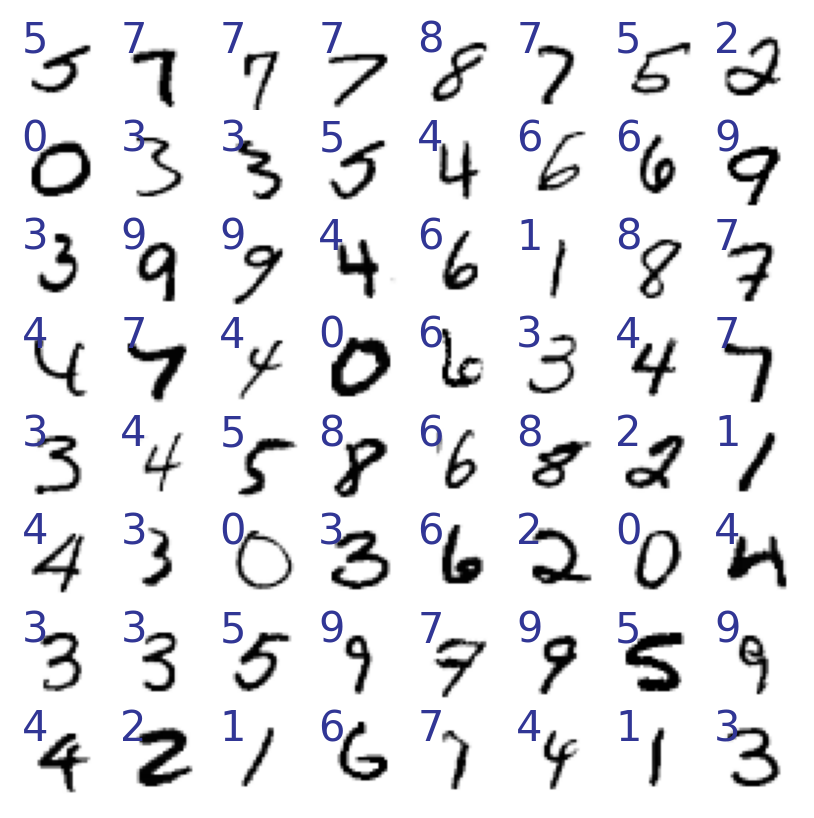

In [ ]:
imgrid(X,digits=y,dim=(8,8),figsize=(5,5))

In [ ]:
X = torch.tensor(X).float()
y = torch.tensor(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [ ]:
rf = RandomForestClassifier(n_estimators=900, n_jobs=-1)
rf.fit(X_train, y_train) 

RandomForestClassifier(n_estimators=900, n_jobs=-1)

In [ ]:
y_train_accuracy = rf.score(X_train, y_train)
y_accuracy = rf.score(X_test, y_test)
y_train_accuracy, y_accuracy

(1.0, 0.973)

In [ ]:
y_pred = rf.predict(X_test)
conf = confusion_matrix(y_test, y_pred)
print(conf)

[[192   0   0   0   0   0   1   0   0   0]
 [  0 219   2   0   0   0   1   0   0   0]
 [  0   0 197   0   2   0   0   1   3   0]
 [  0   1   0 209   0   5   0   0   0   1]
 [  0   0   0   0 179   0   0   0   0   1]
 [  0   0   0   1   0 179   2   0   1   2]
 [  0   0   0   0   0   1 182   0   0   0]
 [  0   0   1   0   2   0   0 216   0   2]
 [  0   2   1   5   1   6   1   0 197   0]
 [  1   0   0   1   0   0   0   4   2 176]]


In [ ]:
def showmatrix(conf):
    df_conf = pd.DataFrame(conf,
                       index=[f"$y$={i}" for i in range(0,9+1)],
                       columns=["$\hat{y}$="+str(i) for i in range(0,9+1)])
    return df_conf

<>:4: SyntaxWarning: invalid escape sequence '\h'
<>:4: SyntaxWarning: invalid escape sequence '\h'
C:\Users\Prasad\AppData\Local\Temp\ipykernel_13040\4106871522.py:4: SyntaxWarning: invalid escape sequence '\h'
  columns=["$\hat{y}$="+str(i) for i in range(0,9+1)])


In [ ]:
showmatrix(conf)

,$\hat{y}$=0,$\hat{y}$=1,$\hat{y}$=2,$\hat{y}$=3,$\hat{y}$=4,$\hat{y}$=5,$\hat{y}$=6,$\hat{y}$=7,$\hat{y}$=8,$\hat{y}$=9
$y$=0,192,0,0,0,0,0,1,0,0,0
$y$=1,0,219,2,0,0,0,1,0,0,0
$y$=2,0,0,197,0,2,0,0,1,3,0
$y$=3,0,1,0,209,0,5,0,0,0,1
$y$=4,0,0,0,0,179,0,0,0,0,1
$y$=5,0,0,0,1,0,179,2,0,1,2
$y$=6,0,0,0,0,0,1,182,0,0,0
$y$=7,0,0,1,0,2,0,0,216,0,2
$y$=8,0,2,1,5,1,6,1,0,197,0
$y$=9,1,0,0,1,0,0,0,4,2,176


In [ ]:
model = nn.Sequential(
    nn.Linear(784, 50), # 50 neurons
    nn.ReLU(),
    nn.Linear(50, 10),  # 10 output classes (0-9)
    nn.Softmax(dim=1)
)

In [ ]:
def ctrain0(model, X, y, learning_rate = .0001, nepochs=2000):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    for epoch in range(nepochs+1):
        y_pred = model(X)
        # Assume model yields softmax probabilities
        loss = F.cross_entropy(y_pred, y)
        if epoch % (nepochs//10) == 0:
            print(f"Epoch {epoch:5d} cross entropy loss {loss:7.4f}")

        optimizer.zero_grad()
        loss.backward() # autograd computes w1.grad, b1.grad, ...
        optimizer.step()
    print(f"LAST        cross entropy loss {loss:7.4f}")

In [ ]:
ctrain0(model, X_train, y_train, learning_rate = .03, nepochs=1000)

c:\Users\Prasad\anaconda3\Lib\site-packages\triton\knobs.py:212: UserWarning: Failed to find cuobjdump.exe
  warnings.warn(f"Failed to find {binary}")
c:\Users\Prasad\anaconda3\Lib\site-packages\triton\knobs.py:212: UserWarning: Failed to find nvdisasm.exe
  warnings.warn(f"Failed to find {binary}")


Epoch     0 cross entropy loss  2.3029
Epoch   100 cross entropy loss  1.4841
Epoch   200 cross entropy loss  1.4796
Epoch   300 cross entropy loss  1.4770
Epoch   400 cross entropy loss  1.4764
Epoch   500 cross entropy loss  1.4761
Epoch   600 cross entropy loss  1.4757
Epoch   700 cross entropy loss  1.4755
Epoch   800 cross entropy loss  1.4752
Epoch   900 cross entropy loss  1.4752
Epoch  1000 cross entropy loss  1.4752
LAST        cross entropy loss  1.4752


In [ ]:
y_proba = model(X_train)
y_proba[0,:].detach().numpy()  # print probabilities for first image

array([6.7553323e-16, 5.3168285e-14, 1.7995283e-09, 5.8523637e-17,
       3.7209626e-05, 5.9337437e-16, 9.9996281e-01, 1.4796166e-20,
       1.3407476e-11, 3.1217741e-16], dtype=float32)

In [ ]:
y_proba.shape

torch.Size([8000, 10])

In [ ]:
y_pred = torch.argmax(y_proba, axis=1)
print(y_pred.shape)
y_pred[0] # what is the predicted digit for the first image?

torch.Size([8000])


tensor(6)

In [ ]:
ncorrect = torch.sum(y_pred==y_train)
train_accur = ncorrect.float() / len(y_train)
print(f"Training accuracy {train_accur:.3f}")

Training accuracy 0.986


In [ ]:
print(f"TRAINING CONFUSION MATRIX {train_accur*100:.1f}%")
conf = confusion_matrix(y_train, y_pred)
showmatrix(conf)

TRAINING CONFUSION MATRIX 98.6%


,$\hat{y}$=0,$\hat{y}$=1,$\hat{y}$=2,$\hat{y}$=3,$\hat{y}$=4,$\hat{y}$=5,$\hat{y}$=6,$\hat{y}$=7,$\hat{y}$=8,$\hat{y}$=9
$y$=0,761,0,0,1,0,0,0,0,0,1
$y$=1,1,797,3,1,1,1,0,2,5,0
$y$=2,0,0,771,5,4,0,1,2,4,0
$y$=3,0,0,5,792,0,1,0,0,1,4
$y$=4,1,2,0,0,823,1,0,0,0,3
$y$=5,4,0,3,7,1,758,1,0,0,3
$y$=6,2,0,2,0,0,1,776,0,0,0
$y$=7,0,1,0,1,2,0,0,866,1,0
$y$=8,0,2,4,4,0,1,0,0,776,1
$y$=9,3,3,0,4,7,2,2,0,2,766


In [ ]:
y_test_proba = model(X_test)
y_test_pred = torch.argmax(y_test_proba, axis=1)
ncorrect = torch.sum(y_test_pred==y_test)
test_accur = ncorrect.float() / len(y_test)
print(f"Validation accuracy {test_accur:.3f}")

Validation accuracy 0.960


In [ ]:
print(f"VALIDATION CONFUSION MATRIX {test_accur*100:.1f}%")
conf = confusion_matrix(y_test, y_test_pred)
showmatrix(conf)

VALIDATION CONFUSION MATRIX 96.0%


,$\hat{y}$=0,$\hat{y}$=1,$\hat{y}$=2,$\hat{y}$=3,$\hat{y}$=4,$\hat{y}$=5,$\hat{y}$=6,$\hat{y}$=7,$\hat{y}$=8,$\hat{y}$=9
$y$=0,187,0,1,1,0,2,1,1,0,0
$y$=1,0,217,2,1,0,0,1,0,1,0
$y$=2,1,0,196,0,1,0,0,2,3,0
$y$=3,1,0,1,208,0,2,0,0,3,1
$y$=4,0,0,0,0,179,0,1,0,0,0
$y$=5,2,0,2,5,1,170,2,0,2,1
$y$=6,0,0,4,0,0,1,177,0,1,0
$y$=7,0,0,1,0,1,0,0,214,0,5
$y$=8,2,2,1,3,0,2,3,0,199,1
$y$=9,2,0,0,4,3,0,0,2,1,172


In [ ]:
def ctrain1(model, X_train, y_train, X_test, y_test, 
            learning_rate = .0001, nepochs=2000):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    for epoch in range(nepochs+1):
        y_pred = model(X_train)
        # Assume model yields softmax probabilities
        loss = F.cross_entropy(y_pred, y_train)
        y_pred = torch.argmax(y_pred, axis=1)
        ncorrect = torch.sum(y_pred==y_train)
        accur = ncorrect.float() / len(y_train)

        y_test_pred = model(X_test)
        loss_test = F.cross_entropy(y_test_pred, y_test)
        y_test_pred = torch.argmax(y_test_pred, axis=1)
        ncorrect = torch.sum(y_test_pred==y_test)
        loss_accur = ncorrect.float() / len(y_test)
        
        history.append((loss, loss_test, accur, loss_accur))
        if epoch % (nepochs//10) == 0:
            print(f"Epoch {epoch:4d} cross entropy loss {loss:7.4f}   test loss {loss_test:7.4f}")

        optimizer.zero_grad()
        loss.backward() # autograd computes w1.grad, b1.grad, ...
        optimizer.step()
    print(f"LAST       cross entropy loss {loss:7.4f}")
    return torch.tensor(history)

In [ ]:
# make sure to create a new model otherwise it starts from where it left off
model = nn.Sequential(
    nn.Linear(784, 50),
    nn.ReLU(),
    nn.Linear(50, 10),  # 10 output classes (0-9)
    nn.Softmax(dim=1)
)

In [ ]:
history = ctrain1(model, X_train, y_train, X_test, y_test,
                  learning_rate = .03, nepochs=1000)

Epoch    0 cross entropy loss  2.3035   test loss  2.3035
Epoch  100 cross entropy loss  1.4838   test loss  1.5100
Epoch  200 cross entropy loss  1.4798   test loss  1.5070
Epoch  300 cross entropy loss  1.4769   test loss  1.5041
Epoch  400 cross entropy loss  1.4758   test loss  1.5039
Epoch  500 cross entropy loss  1.4754   test loss  1.5020
Epoch  600 cross entropy loss  1.4753   test loss  1.5021
Epoch  700 cross entropy loss  1.4751   test loss  1.5018
Epoch  800 cross entropy loss  1.4747   test loss  1.5024
Epoch  900 cross entropy loss  1.4747   test loss  1.5019
Epoch 1000 cross entropy loss  1.4740   test loss  1.5021
LAST       cross entropy loss  1.4740


In [ ]:
y_proba = model(X_train)
y_pred = torch.argmax(y_proba, axis=1)
ncorrect = torch.sum(y_pred==y_train)
train_accur = ncorrect.float() / len(y_train)
print(f"Training accuracy {train_accur:.3f}")

Training accuracy 0.987


In [ ]:
y_test_proba = model(X_test)
y_test_pred = torch.argmax(y_test_proba, axis=1)
ncorrect = torch.sum(y_test_pred==y_test)
test_accur = ncorrect.float() / len(y_test)
print(f"Validation accuracy {test_accur:.3f}")

Validation accuracy 0.958


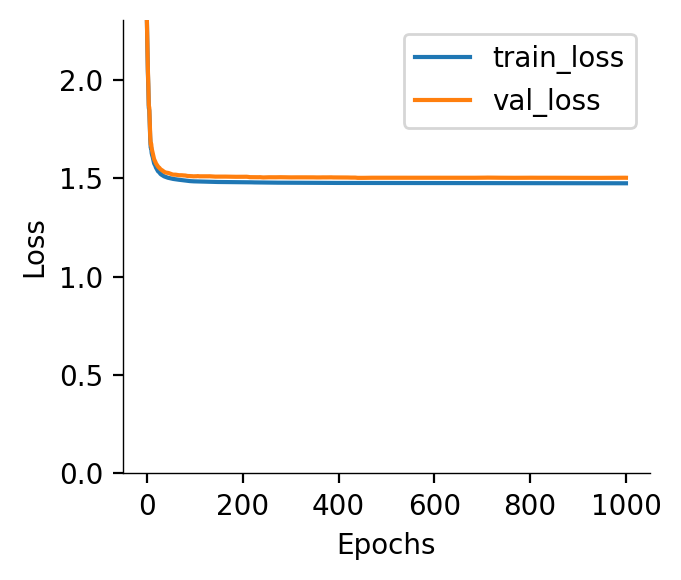

In [ ]:
plot_loss(history)

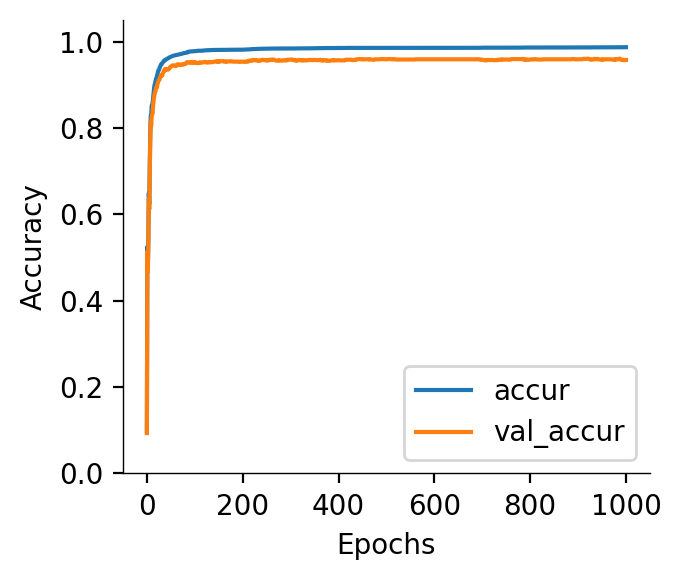

In [ ]:
plot_accur(history)

In [ ]:
model = nn.Sequential(
    nn.Linear(784, 300),
    nn.ReLU(),
    nn.Linear(300, 10),  # 10 output classes (0-9)
    nn.Softmax(dim=1)
)

In [ ]:
history = ctrain1(model, X_train, y_train, X_test, y_test,
                  learning_rate = 0.02, nepochs=1000)

Epoch    0 cross entropy loss  2.3010   test loss  2.3008
Epoch  100 cross entropy loss  1.5824   test loss  1.5874
Epoch  200 cross entropy loss  1.5767   test loss  1.5858
Epoch  300 cross entropy loss  1.5740   test loss  1.5821
Epoch  400 cross entropy loss  1.5717   test loss  1.5808
Epoch  500 cross entropy loss  1.5706   test loss  1.5798
Epoch  600 cross entropy loss  1.5695   test loss  1.5788
Epoch  700 cross entropy loss  1.5682   test loss  1.5799
Epoch  800 cross entropy loss  1.5674   test loss  1.5793
Epoch  900 cross entropy loss  1.5667   test loss  1.5778
Epoch 1000 cross entropy loss  1.5655   test loss  1.5787
LAST       cross entropy loss  1.5655


In [ ]:
y_proba = model(X_train)
y_pred = torch.argmax(y_proba, axis=1)
ncorrect = torch.sum(y_pred==y_train)
train_accur = ncorrect.float() / len(y_train)
print(f"Training accuracy {train_accur:.3f}")

Training accuracy 0.890


In [ ]:
y_test_proba = model(X_test)
y_test_pred = torch.argmax(y_test_proba, axis=1)
ncorrect = torch.sum(y_test_pred==y_test)
test_accur = ncorrect.float() / len(y_test)
print(f"Validation accuracy {test_accur:.3f}")

Validation accuracy 0.877


In [ ]:
conf = confusion_matrix(y_test, y_test_pred.detach().numpy())
print(f"VALIDATION CONFUSION MATRIX {test_accur*100:.1f}%")
showmatrix(conf)

VALIDATION CONFUSION MATRIX 87.8%


,$\hat{y}$=0,$\hat{y}$=1,$\hat{y}$=2,$\hat{y}$=3,$\hat{y}$=4,$\hat{y}$=5,$\hat{y}$=6,$\hat{y}$=7,$\hat{y}$=8,$\hat{y}$=9
$y$=0,192,0,0,0,0,0,1,0,0,0
$y$=1,0,217,2,1,0,0,2,0,0,0
$y$=2,0,2,194,2,0,0,0,2,3,0
$y$=3,0,0,1,206,0,1,0,0,7,1
$y$=4,8,7,13,1,0,24,10,46,20,51
$y$=5,0,0,3,3,0,175,1,0,1,2
$y$=6,0,0,2,0,0,2,177,0,2,0
$y$=7,1,0,1,0,0,0,0,216,1,2
$y$=8,2,2,2,2,0,3,1,0,200,1
$y$=9,1,0,0,1,0,0,0,2,2,178


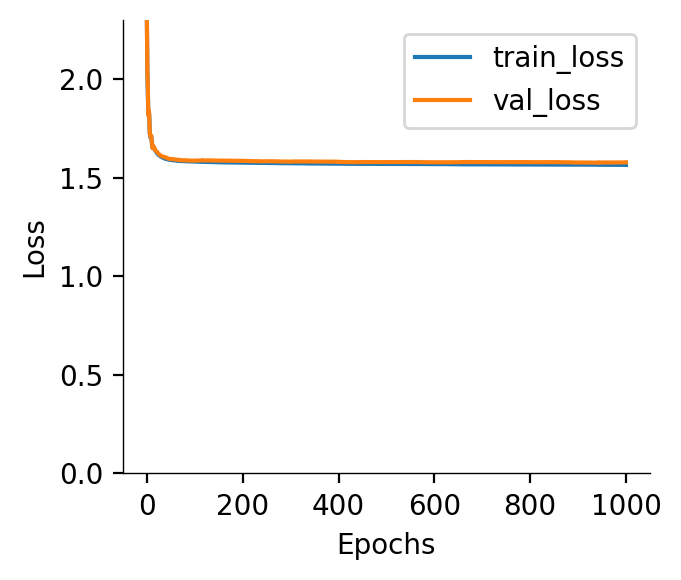

In [ ]:
plot_loss(history)

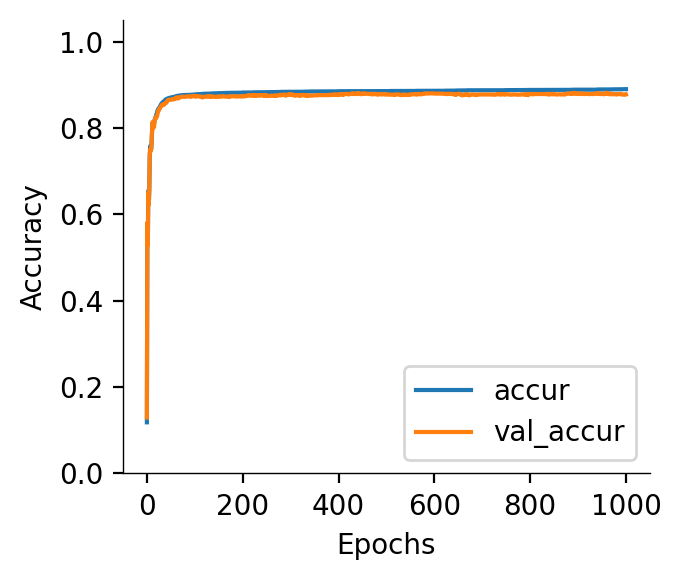

In [ ]:
plot_accur(history)